In [1]:
import numpy as np
from scipy import stats

# Define distribution (loc = mean/shift, scale = std dev/stretch)
dist = stats.norm(loc=0, scale=1)

# Core methods
x = np.linspace(-3, 3, 100)
pdf_vals = dist.pdf(x)          # Probability density function
cdf_vals = dist.cdf(x)          # Cumulative distribution function (P(X <= x))
sf_vals = dist.sf(x)            # Survival function (1 - CDF, P(X > x))
ppf_val = dist.ppf(0.95)        # Percent point function (inverse CDF / quantile)
isf_val = dist.isf(0.05)        # Inverse survival function
samples = dist.rvs(size=1000)   # Generate random variates (samples)

# Summary stats & parameter fitting
mean, var, skew, kurt = dist.stats(moments='mvsk')
params = stats.norm.fit(samples) # Fit distribution parameters to data

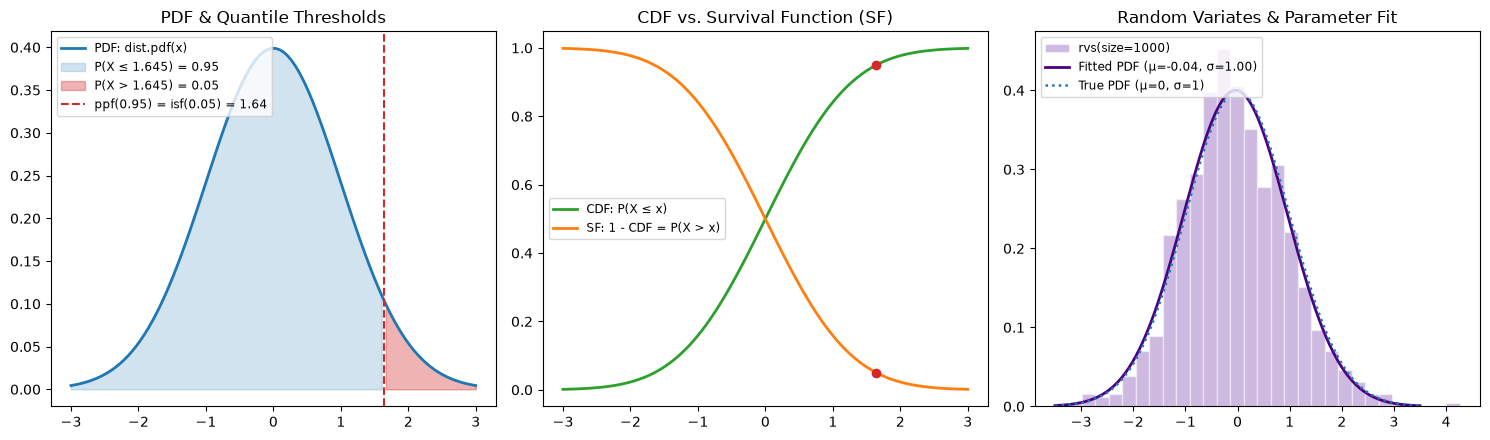

In [2]:
import numpy as np
from scipy import stats

# Define distribution (loc = mean/shift, scale = std dev/stretch)
dist = stats.norm(loc=0, scale=1)

# Core methods
x = np.linspace(-3, 3, 100)
pdf_vals = dist.pdf(x)          # Probability density function
cdf_vals = dist.cdf(x)          # Cumulative distribution function (P(X <= x))
sf_vals = dist.sf(x)            # Survival function (1 - CDF, P(X > x))
ppf_val = dist.ppf(0.95)        # Percent point function (inverse CDF / quantile)
isf_val = dist.isf(0.05)        # Inverse survival function
samples = dist.rvs(size=1000)   # Generate random variates (samples)

# Summary stats & parameter fitting
mean, var, skew, kurt = dist.stats(moments='mvsk')
params = stats.norm.fit(samples) # Fit distribution parameters to data

# --- Visualization of the outputs above ---
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. PDF + PPF / ISF
axes[0].plot(x, pdf_vals, color='#1f77b4', lw=2, label='PDF: dist.pdf(x)')
axes[0].fill_between(x[x <= ppf_val], pdf_vals[x <= ppf_val], color='#1f77b4', alpha=0.2, label='P(X ≤ 1.645) = 0.95')
axes[0].fill_between(x[x >= isf_val], pdf_vals[x >= isf_val], color='#d62728', alpha=0.35, label='P(X > 1.645) = 0.05')
axes[0].axvline(ppf_val, color='#d62728', ls='--', lw=1.5, label=f'ppf(0.95) = isf(0.05) = {ppf_val:.2f}')
axes[0].set_title('PDF & Quantile Thresholds')
axes[0].legend(loc='upper left', fontsize=8.5)

# 2. CDF & Survival Function
axes[1].plot(x, cdf_vals, color='#2ca02c', lw=2, label='CDF: P(X ≤ x)')
axes[1].plot(x, sf_vals, color='#ff7f0e', lw=2, label='SF: 1 - CDF = P(X > x)')
axes[1].scatter([ppf_val, isf_val], [0.95, 0.05], color='#d62728', zorder=5)
axes[1].set_title('CDF vs. Survival Function (SF)')
axes[1].legend(loc='center left', fontsize=8.5)

# 3. Samples Histogram & Fitted Curve
axes[2].hist(samples, bins=30, density=True, color='#9467bd', alpha=0.45, edgecolor='white', label='rvs(size=1000)')
x_fit = np.linspace(-3.5, 3.5, 200)
axes[2].plot(x_fit, stats.norm.pdf(x_fit, *params), color='#4b0082', lw=2,
             label=f'Fitted PDF (μ={params[0]:.2f}, σ={params[1]:.2f})')
axes[2].plot(x_fit, dist.pdf(x_fit), color='#1f77b4', ls=':', lw=1.8, label='True PDF (μ=0, σ=1)')
axes[2].set_title('Random Variates & Parameter Fit')
axes[2].legend(loc='upper left', fontsize=8.5)

plt.tight_layout()
plt.show()